# Analysis Report: Followers and Engagement on Bluesky

**Name:** Sara  
**Date:** November 15, 2026

## Research Question and Hypothesis

**Research Question:** Is there a relationship between the number of followers a news account has on Bluesky and the number of likes its posts receive?

**Hypothesis:** I think news accounts with more followers will generally receive more likes because they have a larger audience.

## Part 1: Dataset Introduction

For this project, I chose to analyze data from Bluesky, a social media platform where people and organizations share content. I chose this topic because I am interested in social media, marketing, and how people interact with online content.

My dataset focuses on news accounts and their recent posts. Each observation represents one post.

The main variables are:

- Followers: The number of followers each account has.
- Likes: The number of likes each post receives.
- Reposts: The number of times a post has been reposted.
- Account: The news account that published the post.

I will mainly focus on the relationship between followers and likes. I will also compare accounts with different audience sizes.

**Source:** Bluesky Public API  
https://docs.bsky.app/docs/api

In [31]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

In [32]:
url = "https://public.api.bsky.app/xrpc/"

accounts = [
    "nytimes.com",
    "theguardian.com",
    "washingtonpost.com",
    "apnews.com",
    "npr.org",
    "reuters.com",
    "theatlantic.com"
]

In [33]:
data = []

for account in accounts:
    profile = requests.get(
        url + "app.bsky.actor.getProfile",
        params={"actor": account},
        timeout=20
    ).json()

    feed = requests.get(
        url + "app.bsky.feed.getAuthorFeed",
        params={"actor": account, "limit": 10},
        timeout=20
    ).json()

    if "followersCount" not in profile or "feed" not in feed:
        print("Could not collect:", account)
        continue

    for item in feed["feed"]:
        post = item["post"]

        data.append({
            "Account": account,
            "Followers": profile["followersCount"],
            "Likes": post.get("likeCount", 0),
            "Reposts": post.get("repostCount", 0),
            "Post ID": post["uri"]
        })

print("Posts collected:", len(data))

Posts collected: 70


In [34]:
df = pd.DataFrame(data)

df = df.drop_duplicates(subset="Post ID")
df = df.dropna()

df.head()

,Account,Followers,Likes,Reposts,Post ID
0,nytimes.com,1358626,24,7,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...
1,nytimes.com,1358626,36,6,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...
2,nytimes.com,1358626,54,7,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...
3,nytimes.com,1358626,52,11,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...
4,nytimes.com,1358626,45,8,at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky...


In [35]:
print("Number of posts:", len(df))
print("Number of accounts:", df["Account"].nunique())

df.info()

Number of posts: 70
Number of accounts: 7
<class 'pandas.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Account    70 non-null     str  
 1   Followers  70 non-null     int64
 2   Likes      70 non-null     int64
 3   Reposts    70 non-null     int64
 4   Post ID    70 non-null     str  
dtypes: int64(3), str(2)
memory usage: 8.5 KB


In [36]:
print("Missing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
print(df[["Followers", "Likes", "Reposts"]].describe())

Missing values:
Account      0
Followers    0
Likes        0
Reposts      0
Post ID      0
dtype: int64

Summary statistics:
          Followers       Likes     Reposts
count  7.000000e+01   70.000000   70.000000
mean   7.403426e+05   81.614286   17.557143
std    3.575785e+05  123.262803   26.941502
min    3.563210e+05    2.000000    0.000000
25%    3.630900e+05   16.750000    3.250000
50%    7.998450e+05   41.500000    7.000000
75%    1.018026e+06   87.000000   19.500000
max    1.358626e+06  746.000000  179.000000



### Preparing the Data

I used the Bluesky API to collect recent posts from seven news accounts. I organized the information into a pandas DataFrame and checked the data types and missing values.

I also removed duplicate posts using their post IDs. This was important because I wanted each post to appear only once in my analysis.

The dataset includes numerical information about followers, likes, and reposts, along with the account names.



## Part 2: Exploring the Data

### Histogram: Distribution of Likes

I started by looking at how likes are distributed across the posts. This helps me understand whether most posts receive similar engagement or if some posts receive much more attention.


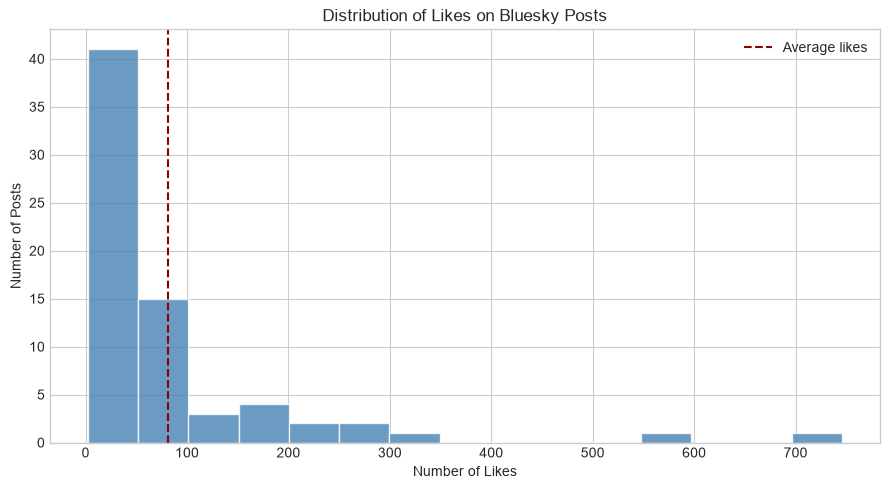

In [38]:
plt.figure(figsize=(9, 5))

plt.hist(df["Likes"], bins=15,
         color="steelblue", edgecolor="white", alpha=0.8)

plt.axvline(df["Likes"].mean(), color="darkred",
            linestyle="--", label="Average likes")

plt.title("Distribution of Likes on Bluesky Posts")
plt.xlabel("Number of Likes")
plt.ylabel("Number of Posts")
plt.legend()

plt.tight_layout()
plt.show()

In [39]:
print("Average likes:", round(df["Likes"].mean(), 2))
print("Median likes:", df["Likes"].median())
print("Maximum likes:", df["Likes"].max())
print("Minimum likes:", df["Likes"].min())

Average likes: 81.61
Median likes: 41.5
Maximum likes: 746
Minimum likes: 2



### Histogram Interpretation

The histogram shows how likes are distributed across the posts in my dataset. I used 15 bins to separate the likes into ranges, making it easier to see where most posts fall.

The average line helps compare the overall average with the distribution. Using fewer bins would make the graph more general, while more bins would show smaller differences between posts.


### Scatter Plot: Followers and Likes

For my second visualization, I compared the number of followers an account has with the likes its posts receive.

I wanted to see whether accounts with larger audiences generally receive more engagement.

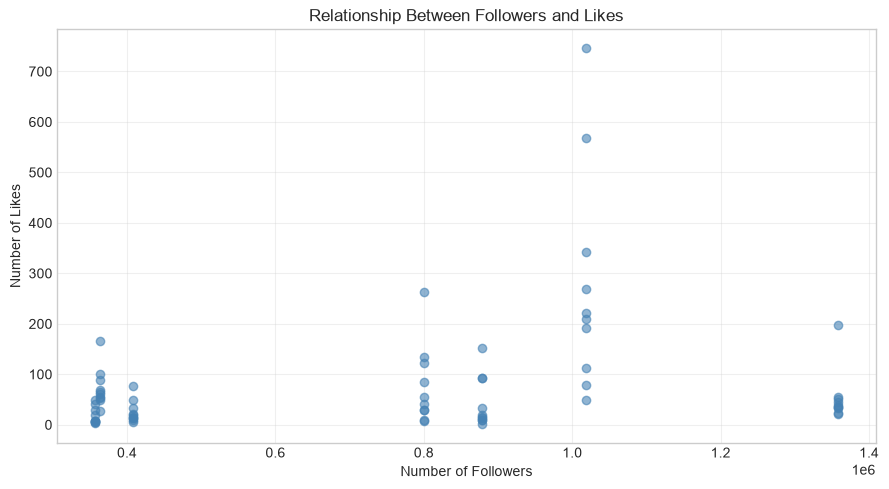

In [40]:
plt.figure(figsize=(9, 5))

plt.scatter(df["Followers"], df["Likes"],
            color="steelblue", alpha=0.6)

plt.title("Relationship Between Followers and Likes")
plt.xlabel("Number of Followers")
plt.ylabel("Number of Likes")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
correlation = df["Followers"].corr(df["Likes"])

print("Correlation:", round(correlation, 3))

Correlation: 0.258


### Scatter Plot Interpretation

The scatter plot shows the relationship between the number of followers and the likes received by individual posts.

Each point represents one post. I used transparency to make overlapping points easier to see.

Since each account has multiple posts, some points share the same follower count. This graph helps me compare audience size and engagement, but it does not prove that having more followers causes more likes.

### Boxplot: Comparing Follower Groups

For my third visualization, I divided the accounts into two groups based on their follower counts.

I wanted to compare the typical number of likes and see whether engagement varies between accounts with smaller and larger audiences.


In [42]:
account_followers = df.groupby("Account")["Followers"].first()

median_followers = account_followers.median()

df["Follower Group"] = "Lower Followers"

df.loc[df["Followers"] >= median_followers,
       "Follower Group"] = "Higher Followers"

print(df["Follower Group"].value_counts())

Follower Group
Higher Followers    40
Lower Followers     30
Name: count, dtype: int64


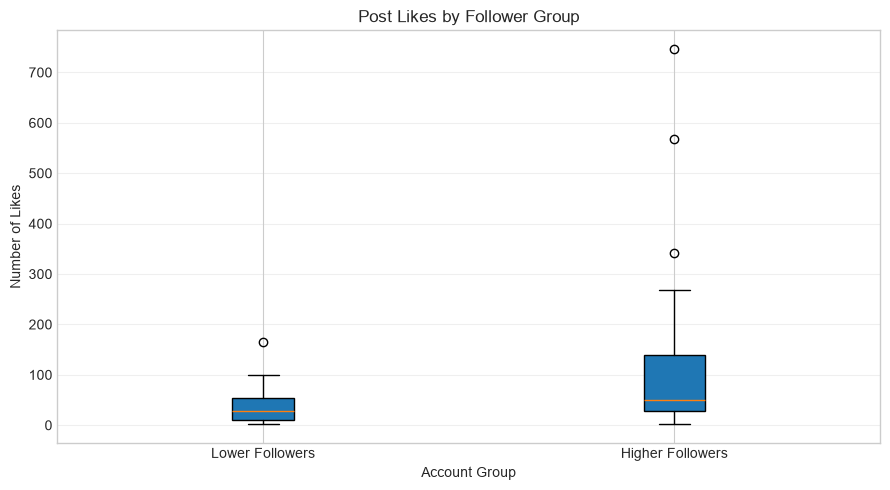

In [43]:
lower = df[df["Follower Group"] == "Lower Followers"]["Likes"]
higher = df[df["Follower Group"] == "Higher Followers"]["Likes"]

plt.figure(figsize=(9, 5))

plt.boxplot(
    [lower, higher],
    tick_labels=["Lower Followers", "Higher Followers"],
    patch_artist=True
)

plt.title("Post Likes by Follower Group")
plt.xlabel("Account Group")
plt.ylabel("Number of Likes")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
print("Median likes by group:")
print(df.groupby("Follower Group")["Likes"].median())

print("\nAverage likes by group:")
print(df.groupby("Follower Group")["Likes"].mean())

Median likes by group:
Follower Group
Higher Followers    50.5
Lower Followers     28.5
Name: Likes, dtype: float64

Average likes by group:
Follower Group
Higher Followers    113.600000
Lower Followers      38.966667
Name: Likes, dtype: float64


### Boxplot Interpretation

The boxplot shows that accounts with more followers had a higher median number of likes per post (50.5) compared to accounts with fewer followers (28.5).

This suggests that larger accounts generally received more engagement in my dataset. However, there was still variation within both groups, meaning that having more followers does not guarantee that every post will receive more likes.

I found this graph useful because it made the differences between the two groups easier to compare.

## Part 3: Visualization Design

I wanted my graphs to look consistent and be easy to understand, so I used similar colors, clear titles, and readable labels.

I adjusted the figure sizes to make the graphs easier to read. I also used a matplotlib style sheet and added gridlines where they helped compare values.

For the histogram, I used 15 bins and added a reference line for the average. For the scatter plot, I used transparency so overlapping points would be easier to see.

I also used tight_layout to keep the labels and titles organized.

I tried to keep the design simple because I wanted the audience to focus on the information rather than unnecessary details.

## Part 4: Statistical Analysis

I used correlation to investigate the relationship between the number of followers and likes.

My independent variable X is the number of followers, and my dependent variable (Y) is the number of likes received by a post.

A positive correlation would suggest that accounts with more followers tend to receive more likes. A negative correlation would suggest the opposite.

Correlation describes the direction and strength of a relationship, but it does not prove causation.

In [45]:
correlation = df["Followers"].corr(df["Likes"])

print("Correlation:", round(correlation, 3))

if correlation > 0.5:
    print("The relationship is positive and relatively strong.")
elif correlation > 0:
    print("The relationship is positive but weak.")
elif correlation < -0.5:
    print("The relationship is negative and relatively strong.")
elif correlation < 0:
    print("The relationship is negative but weak.")
else:
    print("There is no linear correlation.")

Correlation: 0.258
The relationship is positive but weak.


### Statistical Analysis Interpretation

The correlation between followers and likes was 0.258, showing a weak positive relationship. This means that accounts with more followers tended to receive slightly more likes, but the relationship was not very strong.

My hypothesis was partially supported because the relationship was positive, although weaker than I expected.

One limitation is that I used multiple posts from the same accounts, so the observations are not completely independent. Other factors, such as the topic of a post or when it was published, could also influence engagement.

## Part 5: Conclusions and Reflection

This project helped me understand how follower counts and engagement are related on Bluesky.

At first, I expected news accounts with more followers to receive more likes. My results partially supported this idea. The correlation was 0.258, which shows a weak positive relationship between followers and likes.

I found the boxplot especially useful because it showed that accounts with more followers had a higher median of 50.5 likes, compared to 28.5 likes for accounts with fewer followers. However, the engagement still varied between posts.

The statistical analysis helped me understand that even though larger accounts tended to receive more likes, the overall relationship was weaker than I expected.

One limitation of my dataset is that I only analyzed 70 posts from seven news accounts. I also did not consider the topics of the posts, when they were published, or how active each account's audience was.

If I continued this research, I would collect more posts from different types of accounts and compare content categories. This could help explain why some posts receive more engagement than others.

Overall, I learned that having more followers can be related to higher engagement, but follower count alone does not explain how well a post performs.

In [47]:
print("FINAL RESULTS")

print("Total posts:", len(df))
print("Total accounts:", df["Account"].nunique())
print("Correlation:", round(df["Followers"].corr(df["Likes"]), 3))

print("\nMedian likes by group:")
print(df.groupby("Follower Group")["Likes"].median())

print("\nMissing values:")
print(df.isnull().sum())

FINAL RESULTS
Total posts: 70
Total accounts: 7
Correlation: 0.258

Median likes by group:
Follower Group
Higher Followers    50.5
Lower Followers     28.5
Name: Likes, dtype: float64

Missing values:
Account           0
Followers         0
Likes             0
Reposts           0
Post ID           0
Follower Group    0
dtype: int64
